# Grassmannian Diagnostics — Illustrated Walkthrough

Reference implementations of the diagnostics introduced in *From Parameters to Subspaces: The Geometry of Complexity in Asset Pricing* live in [`src/diagnostics/`](../../src/diagnostics/). This notebook exercises each of them on small, controlled synthetic examples so you can build intuition for what each number measures.

Coverage:

1. **Effective rank** (= intrinsic dimension, §4.1) — on a signal+noise spectrum.
2. **Spectral gap** (§6) — the same spectrum, scanned across candidate boundaries `k`.
3. **Eigengap curvature** (§6) — per-direction analogue of the spectral gap.
4. **Principal angles, Grassmann distance, anisotropy ratio** (§4.2) — between two fitted subspaces with known prescribed angles, and on a noise-perturbed re-fit.
5. **Geodesic acceleration** (§6) — along a trajectory of rolling-window subspaces with a planted regime shift.

In [1]:
import math
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

# Make `src` importable when running from notebooks/examples/.
project_root = Path.cwd().parents[1] if Path.cwd().name == "examples" else Path.cwd()
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from src.diagnostics import (
    anisotropy_ratio,
    effective_rank,
    eigengap_curvature,
    geodesic_acceleration,
    grassmann_distance,
    intrinsic_dimension,
    principal_angles,
    projection_distance,
    spectral_gap,
)

rng = np.random.default_rng(42)
plt.rcParams["figure.dpi"] = 110

## 1. Effective rank on a signal+noise spectrum

We construct a covariance with `k_0 = 3` dominant signal directions and a flat noise floor of dimension `7`. The effective rank should track the noise floor: when the noise floor is small, `erank ≈ k_0`; when it grows, `erank` inflates toward the ambient dimension.

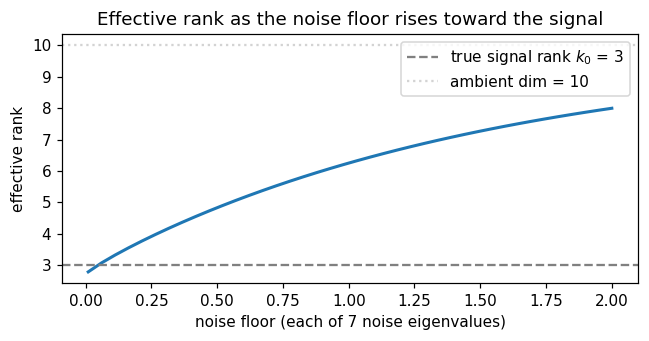

intrinsic_dimension is an alias: 2.7000 == 2.7000


In [2]:
k_0 = 3
n_noise = 7
signal_eigenvalues = np.array([10.0, 6.0, 3.0])
noise_floors = np.linspace(0.01, 2.0, 40)

erank_values = []
for floor in noise_floors:
    spectrum = np.concatenate([signal_eigenvalues, np.full(n_noise, floor)])
    erank_values.append(effective_rank(spectrum))

fig, ax = plt.subplots(figsize=(6, 3.2))
ax.plot(noise_floors, erank_values, lw=2)
ax.axhline(k_0, ls="--", color="gray", label=f"true signal rank $k_0$ = {k_0}")
ax.axhline(k_0 + n_noise, ls=":", color="lightgray", label=f"ambient dim = {k_0 + n_noise}")
ax.set_xlabel("noise floor (each of 7 noise eigenvalues)")
ax.set_ylabel("effective rank")
ax.set_title("Effective rank as the noise floor rises toward the signal")
ax.legend()
fig.tight_layout()
plt.show()

print(f"intrinsic_dimension is an alias: {intrinsic_dimension(signal_eigenvalues):.4f} == {effective_rank(signal_eigenvalues):.4f}")

## 2. Spectral gap at a candidate signal/noise boundary

Same spectrum, fixed noise floor. We scan `k = 1 .. n−1` and plot the normalized gap. The diagnostic should be largest at `k = k_0` (the true boundary) and drop off sharply on either side.

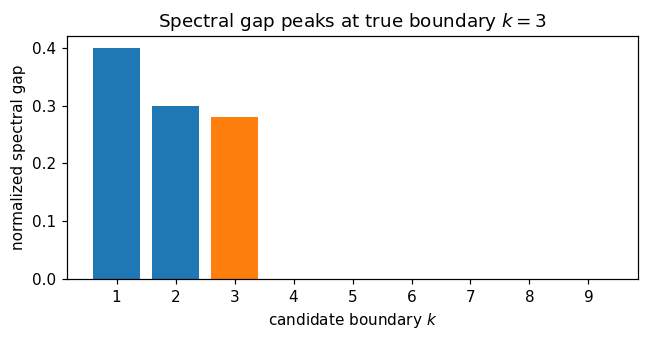

In [3]:
spectrum = np.concatenate([signal_eigenvalues, np.full(n_noise, 0.2)])
ks = np.arange(1, len(spectrum))
gaps = [spectral_gap(spectrum, k=int(k)) for k in ks]

fig, ax = plt.subplots(figsize=(6, 3.2))
ax.bar(ks, gaps, color=["C1" if k == k_0 else "C0" for k in ks])
ax.set_xlabel("candidate boundary $k$")
ax.set_ylabel("normalized spectral gap")
ax.set_title(f"Spectral gap peaks at true boundary $k = {k_0}$")
ax.set_xticks(ks)
fig.tight_layout()
plt.show()

## 3. Eigengap curvature — per direction

`spectral_gap` collapses the spectrum to a scalar at one boundary. `eigengap_curvature(eigenvalues, k)` returns the per-direction gaps `λ_j − λ_{k+1}` for `j ≤ k`. Per §6, these approximate the local curvature of the Grassmann projection objective along each retained direction; small entries flag weakly identified directions that rotate under perturbation.

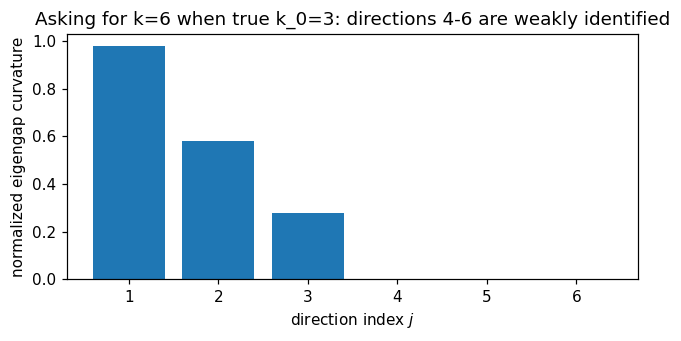

In [4]:
# Overshoot the true rank: ask for k = 6 retained directions when k_0 = 3.
curvature = eigengap_curvature(spectrum, k=6)

fig, ax = plt.subplots(figsize=(6, 3.2))
ax.bar(np.arange(1, 7), curvature, color=["C0" if j < k_0 else "C3" for j in range(6)])
ax.set_xlabel("direction index $j$")
ax.set_ylabel("normalized eigengap curvature")
ax.set_title(
    f"Asking for k=6 when true k_0={k_0}: directions 4-6 are weakly identified"
)
fig.tight_layout()
plt.show()

## 4. Principal angles, Grassmann distance, anisotropy ratio

We construct two 3-dimensional subspaces in $\mathbb{R}^{10}$ with prescribed principal angles, then verify the diagnostics recover them. We also compare a *concentrated* drift (one big angle, two small) with a *diffuse* drift (three equal angles).

In [5]:
def two_subspaces_with_angles(angles):
    k = len(angles)
    n = 2 * k
    basis_a = np.zeros((n, k))
    basis_b = np.zeros((n, k))
    for j, psi in enumerate(angles):
        basis_a[j, j] = 1.0
        basis_b[j, j] = math.cos(psi)
        basis_b[k + j, j] = math.sin(psi)
    return basis_a, basis_b

concentrated_prescribed = [0.02, 0.04, 0.9]
diffuse_prescribed = [0.35, 0.35, 0.35]

for label, prescribed in [
    ("concentrated drift", concentrated_prescribed),
    ("diffuse drift", diffuse_prescribed),
]:
    basis_a, basis_b = two_subspaces_with_angles(prescribed)
    recovered = principal_angles(basis_a, basis_b)
    print(f"--- {label} ---")
    print(f"  prescribed angles (sorted): {sorted(prescribed)}")
    print(f"  recovered angles:           {recovered.round(6).tolist()}")
    print(f"  grassmann_distance (geodesic):   {grassmann_distance(basis_a, basis_b):.4f}")
    print(f"  grassmann_distance (projection): {grassmann_distance(basis_a, basis_b, metric='projection'):.4f}")
    print(f"  projection_distance:             {projection_distance(basis_a, basis_b):.4f}")
    print(f"  anisotropy ratio rho_psi:        {anisotropy_ratio(recovered):.4f}")
    print()

--- concentrated drift ---
  prescribed angles (sorted): [0.02, 0.04, 0.9]
  recovered angles:           [0.02, 0.04, 0.9]
  grassmann_distance (geodesic):   0.9011
  grassmann_distance (projection): 0.7846
  projection_distance:             0.7846
  anisotropy ratio rho_psi:        0.3556

--- diffuse drift ---
  prescribed angles (sorted): [0.35, 0.35, 0.35]
  recovered angles:           [0.35, 0.35, 0.35]
  grassmann_distance (geodesic):   0.6062
  grassmann_distance (projection): 0.5939
  projection_distance:             0.5939
  anisotropy ratio rho_psi:        1.0000



Concentrated drift has `rho_psi` close to 0 (most rotation in one direction). Diffuse drift has `rho_psi` close to 1 (rotation spread evenly). Paper §1 motivates `rho_psi` as a diagnostic for distinguishing structured regime shifts from diffuse noise-driven instability.

## 5. Geodesic acceleration along a subspace trajectory

We simulate a rolling-window trajectory of 2-dim subspaces in $\mathbb{R}^6$. For the first half, the subspace drifts at a small constant rate (smooth path → small acceleration). At the midpoint we inject a regime shift (kink → large acceleration). We compute the three-point acceleration at each interior window.

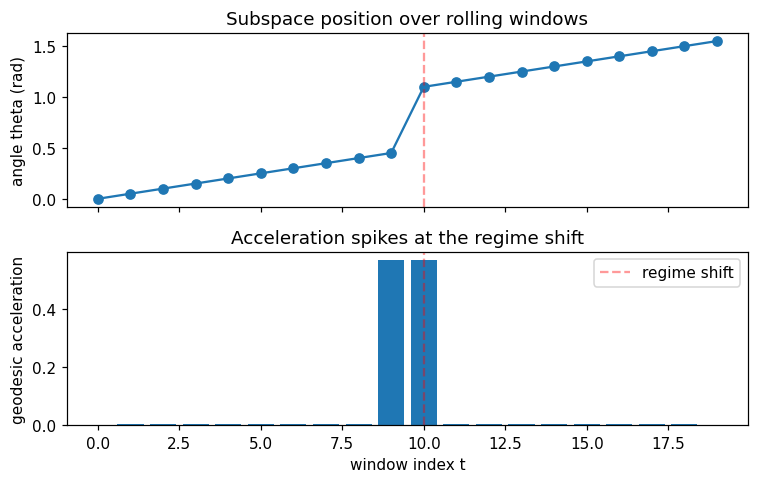

In [6]:
def basis_at_angle(theta):
    """2D subspace inside R^6 obtained by rotating e_2 toward e_3 by theta,
    and shifting the overall position by an extra `theta` jump at t = midpoint."""
    b = np.zeros((6, 2))
    b[0, 0] = 1.0
    b[1, 1] = math.cos(theta)
    b[2, 1] = math.sin(theta)
    return b

num_windows = 20
regime_shift_at = 10

thetas = []
for t in range(num_windows):
    base = 0.05 * t  # smooth drift
    if t >= regime_shift_at:
        base += 0.6  # one-time regime shift
    thetas.append(base)
thetas = np.array(thetas)

trajectory = [basis_at_angle(theta) for theta in thetas]

accelerations = []
for t in range(1, num_windows - 1):
    a = geodesic_acceleration(trajectory[t - 1], trajectory[t], trajectory[t + 1])
    accelerations.append(a)

fig, axes = plt.subplots(2, 1, figsize=(7, 4.5), sharex=True)
axes[0].plot(thetas, marker="o")
axes[0].set_ylabel("angle theta (rad)")
axes[0].set_title("Subspace position over rolling windows")
axes[0].axvline(regime_shift_at, ls="--", color="red", alpha=0.4)

axes[1].bar(range(1, num_windows - 1), accelerations)
axes[1].axvline(regime_shift_at, ls="--", color="red", alpha=0.4, label="regime shift")
axes[1].set_xlabel("window index t")
axes[1].set_ylabel("geodesic acceleration")
axes[1].set_title("Acceleration spikes at the regime shift")
axes[1].legend()
fig.tight_layout()
plt.show()

## Summary

| Diagnostic | What it measures | Interpretation |
|---|---|---|
| `effective_rank` / `intrinsic_dimension` | how many directions are effectively active in `Σ̂_f` | low → noise-dominated; near `k` → all retained directions carry variance |
| `spectral_gap` | size of the gap at a candidate boundary `k` | large → well-identified rank; collapsed → no clear boundary |
| `eigengap_curvature` | per-direction analogue of the spectral gap | small entries flag weakly identified directions that will rotate under perturbation |
| `principal_angles` | rotation between two subspaces, decomposed by direction | basis of all subspace-stability diagnostics |
| `grassmann_distance` / `projection_distance` | scalar dissimilarity between two subspaces | aggregate stability |
| `anisotropy_ratio` | mean / max principal angle | concentration of subspace drift in few directions |
| `geodesic_acceleration` | discrete second difference along a subspace trajectory | flat between regimes, spikes at structural breaks |
